In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import torch
import numpy as np
from transformers import GPT2Tokenizer, GPT2LMHeadModel

c:\Users\Yang Qing\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\utils\_pytree.py:185: FutureWarning: optree is installed but the version is too old to support PyTorch Dynamo in C++ pytree. C++ pytree support is disabled. Please consider upgrading optree using `python3 -m pip install --upgrade 'optree>=0.13.0'`.
  warnings.warn(
c:\Users\Yang Qing\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Directories containing the medical notes
gpt_note_dir = r"C:\Users\Yang Qing\OneDrive\Desktop\ADS Evaluation\Medical notes by ChatGPT 4o\Original notes"
llama_note_dir = r"C:\Users\Yang Qing\OneDrive\Desktop\ADS Evaluation\Medical notes by ChatGPT 4o\With repetation\1"

In [3]:

# Load GPT-2 tokenizer and model
tokenizer = GPT2Tokenizer.from_pretrained("gpt2")
model = GPT2LMHeadModel.from_pretrained("gpt2")
model.eval()  # Set model to evaluation mode

def chunk_text(text, chunk_size=1024, overlap=200):
    """Splits text into overlapping chunks to avoid truncation issues."""
    tokens = tokenizer.encode(text, add_special_tokens=True)
    chunks = []
    start = 0
    while start < len(tokens):
        end = min(start + chunk_size, len(tokens))
        chunks.append(tokens[start:end])
        start += chunk_size - overlap  # Overlap chunks to maintain context
    return chunks

def calculate_perplexity(text):
    """Calculates perplexity for long text by splitting into chunks."""
    if not text.strip():
        return float("inf"), 0  # Return infinity if text is empty
    
    chunks = chunk_text(text)
    total_loss = 0
    total_tokens = 0

    for chunk in chunks:
        encodings = torch.tensor(chunk).unsqueeze(0)  # Convert to tensor
        with torch.no_grad():
            outputs = model(input_ids=encodings, labels=encodings)
            loss = outputs.loss
            chunk_perplexity = torch.exp(loss).item()
        
        total_loss += loss.item() * len(chunk)  # Weight by token count
        total_tokens += len(chunk)
    
    avg_perplexity = torch.exp(torch.tensor(total_loss / total_tokens)).item() if total_tokens > 0 else float("inf")

    return avg_perplexity, total_tokens

def evaluate_perplexity(directory, source_name):
    """Calculates perplexity for each text file without truncation."""
    data = []
    for filename in os.listdir(directory):
        if filename.endswith(".txt"):
            file_path = os.path.join(directory, filename)
            with open(file_path, "r", encoding="utf-8",  errors="ignore") as file:
                text = file.read()
                perplexity, num_tokens = calculate_perplexity(text)
                perplexity_per_token = perplexity / num_tokens if num_tokens > 0 else float("inf")
                data.append({
                    "Filename": filename,
                    "Perplexity": perplexity,
                    "Tokens": num_tokens,
                    "Perplexity Per Token": perplexity_per_token,
                    "Source": source_name
                })
    
    return pd.DataFrame(data)

# Calculate perplexity without truncation
df_gpt = evaluate_perplexity(gpt_note_dir, "GPT")
df_llama = evaluate_perplexity(llama_note_dir, "LLaMA")

# Combine results
df_perplexity = pd.concat([df_gpt, df_llama], ignore_index=True)


In [4]:
df_perplexity["Filename"] = df_perplexity["Filename"].str[:16]
df = df_perplexity.pivot(index="Filename", columns="Source", values="Perplexity").reset_index()
df.columns = ["Filename", "GPT Perplexity", "LLaMA Perplexity"]  # Rename columns

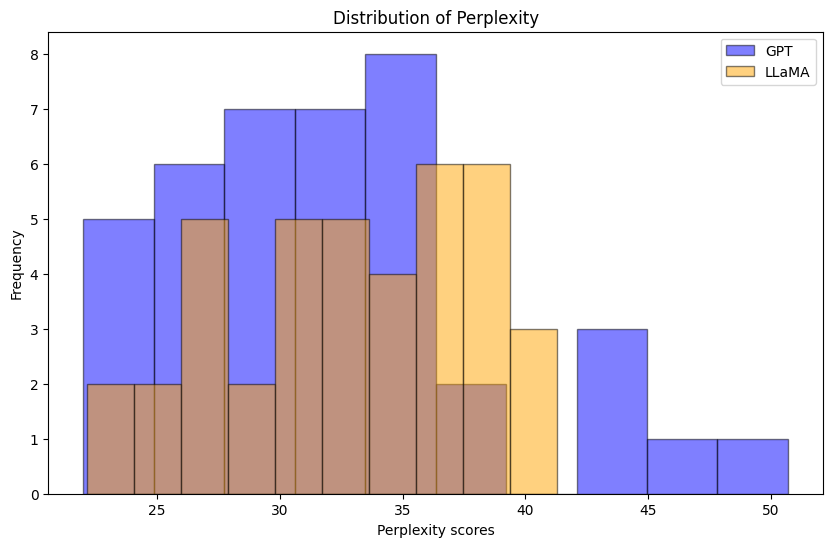

In [12]:
plt.figure(figsize=(10, 6))
plt.hist(df['GPT Perplexity'], bins=10, alpha=0.5, label='GPT', color='blue', edgecolor='black')
plt.hist(df['LLaMA Perplexity'], bins=10, alpha=0.5, label='LLaMA', color='orange', edgecolor='black')
plt.title('Distribution of Perplexity')
plt.xlabel('Perplexity scores')
plt.ylabel('Frequency')
plt.legend(loc='upper right')
plt.show()

In [13]:
# Define the save directory and file path
save_dir = r"C:\Users\Yang Qing\OneDrive\Desktop\ADS Evaluation\Figures\High dpi paper for technical check\Figure 4a"
save_path = os.path.join(save_dir, "Perplexity_Distribution.png")

# Create the histogram plot
plt.figure(figsize=(10, 6))
plt.hist(df['GPT Perplexity'], bins=10, alpha=0.5, label='GPT', color='blue', edgecolor='black')
plt.hist(df['LLaMA Perplexity'], bins=10, alpha=0.5, label='LLaMA', color='orange', edgecolor='black')

# Add labels and legend
plt.xlabel('Perplexity scores', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.legend(loc='upper right')

# Save the figure at 300 DPI
plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.close()

print(f"Figure saved successfully at: {save_path}")
plt.show()

Figure saved successfully at: C:\Users\Yang Qing\OneDrive\Desktop\ADS Evaluation\Figures\High dpi paper for technical check\Figure 4a\Perplexity_Distribution.png


In [6]:
print(f"Perplexity for GPT is {df['GPT Perplexity'].mean()}")
print(f"Perplexity for LLaMA is {df['LLaMA Perplexity'].mean()}")


Perplexity for GPT is 32.234910535812375
Perplexity for LLaMA is 33.09566626548767


In [7]:
import scipy.stats as stats

# Conduct paired t-test
t_stat, p_value = stats.ttest_rel(df['GPT Perplexity'], df['LLaMA Perplexity'])

# Print results
print(f"Paired t-test results: t-statistic = {t_stat:.4f}, p-value = {p_value:.4f}")


Paired t-test results: t-statistic = -0.6551, p-value = 0.5163


In [8]:
df.head()

,Filename,GPT Perplexity,LLaMA Perplexity
0,DC0001 - DPt0411,36.589619,35.270885
1,DC0026 - DPt0326,35.496933,27.691811
2,DC0026 - DPt0529,29.138548,35.677681
3,DC0027 - DPt0596,34.381741,37.264454
4,DC0028 - DPt0506,34.172386,33.338947


## Using Result from Rui

In [9]:
file_path = r"C:\Users\Yang Qing\OneDrive\Desktop\ADS Evaluation\Codes\Perplexity\perplexity.csv"
df = pd.read_csv(file_path)


FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\Yang Qing\\OneDrive\\Desktop\\ADS Evaluation\\Codes\\Perplexity\\perplexity.csv'

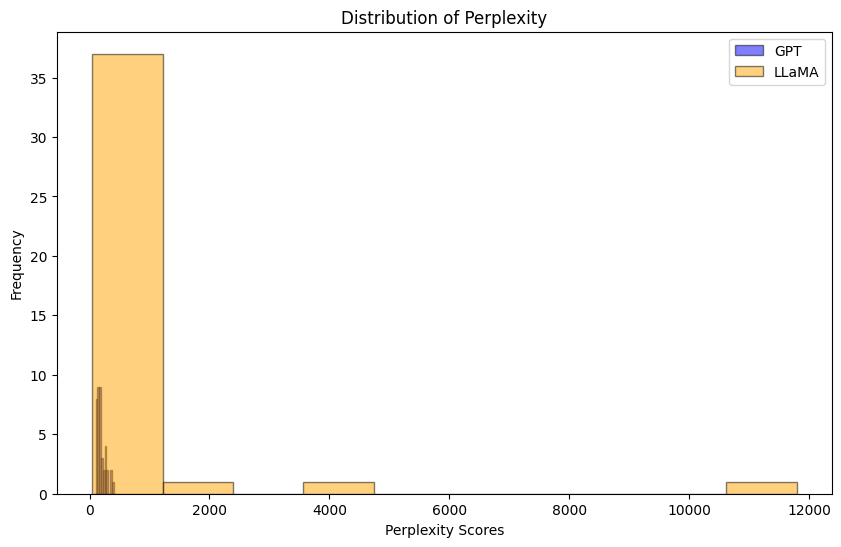

In [ ]:
plt.figure(figsize=(10, 6))
plt.hist(df['gpt_perplexity'], bins=10, alpha=0.5, label='GPT', color='blue', edgecolor='black')
plt.hist(df['llama_perplexity'], bins=10, alpha=0.5, label='LLaMA', color='orange', edgecolor='black')
plt.title('Distribution of Perplexity')
plt.xlabel('Perplexity Scores')
plt.ylabel('Frequency')
plt.legend(loc='upper right')
plt.show()

In [ ]:
df.head(10)

,file_name,gpt_perplexity,llama_perplexity
0,DC0001 - DPt0411 edited_deidentified_note.txt,274.690269,140.589456
1,DC0026 - DPt0326 edited_deidentified_note.txt,124.286817,64.848586
2,DC0026 - DPt0529 edited_deidentified_note.txt,124.378802,60.838514
3,DC0027 - DPt0596 edited_deidentified_note.txt,220.422493,69.778149
4,DC0028 - DPt0506 edited_deidentified_note.txt,102.895543,75.437279
5,DC0033 - DPt0530 edited_deidentified_note.txt,152.663900,64.058464
6,DC0033 - DPt0564 edited_deidentified_note.txt,180.207361,70.422669
7,DC0034 - DPt0329 edited_deidentified_note.txt,218.303911,4546.719881
8,DC0042 - DPt0510 edited_deidentified_note.txt,158.443544,442.593868
9,DC0042 - DPt0527 edited_deidentified_note.txt,170.729632,461.079456
